# Formula 1 Strategy Intelligence Platform — Advanced Analytics Notebook

**Purpose:** the analyses that genuinely need Python rather than DAX — clustering,
outlier detection, regression, forecasting, degradation modeling, and a strategy
simulation. Each of these is a one-time model fit or classification, so results are
exported as static columns/flags that Power BI consumes directly, rather than
attempted as DAX measures that would need to recompute per filter context for no
real benefit.

**Inputs:** cleaned tables from `etl.ipynb` (`./data/processed/`) and engineered
features from `feature_engineering.ipynb` (`./data/features/`).

**Sections:**
1. Driver clustering (K-Means) — natural performance segments
2. Pit stop clustering — data-driven strategic windows per circuit
3. Outlier detection — anomalous pit stops & laps (safety car artifacts)
4. Reliability regression — DNF probability by constructor/circuit/season
5. Season points forecasting — projected final standings from a partial season
6. Race pace & degradation — per-stint slope fitting
7. Strategy simulation — undercut/overcut expected value model

This is the piece that differentiates the project from a standard reporting
dashboard — build it once the core 8-page report already works, so it reads as
an enhancement layer, not a blocker.


## 0. Imports & Load Data

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

PROCESSED_DIR = Path('../data/processed')
FEATURES_DIR = Path('../data/features')
OUT_DIR = Path('../data/advanced')
OUT_DIR.mkdir(parents=True, exist_ok=True)

results_df       = pd.read_parquet(PROCESSED_DIR / 'results.parquet')
races_df         = pd.read_parquet(PROCESSED_DIR / 'races.parquet')
drivers_df       = pd.read_parquet(PROCESSED_DIR / 'drivers.parquet')
constructors_df  = pd.read_parquet(PROCESSED_DIR / 'constructors.parquet')
pit_stops_df     = pd.read_parquet(PROCESSED_DIR / 'pit_stops.parquet')
lap_times_df     = pd.read_parquet(PROCESSED_DIR / 'lap_times.parquet')

stints_df        = pd.read_parquet(FEATURES_DIR / 'stints.parquet')
teammate_deltas  = pd.read_parquet(FEATURES_DIR / 'teammate_deltas.parquet')
rolling_form_df  = pd.read_parquet(FEATURES_DIR / 'rolling_form.parquet')

results_df = results_df.merge(
    races_df[['raceId', 'Season', 'Round', 'race_date', 'circuitId']],
    on='raceId', how='left'
)

print("Data loaded:", {n: len(d) for n, d in {
    'results': results_df, 'stints': stints_df,
    'teammate_deltas': teammate_deltas, 'rolling_form': rolling_form_df
}.items()})


Data loaded: {'results': 27323, 'stints': 39377, 'teammate_deltas': 3585, 'rolling_form': 27323}


## 1. Driver Clustering (K-Means)

Clusters driver-seasons on pace, consistency, and reliability features to surface
natural groupings ("front-runners," "midfield consistent," "high-variance
backmarkers") without hand-coding thresholds. Output feeds a `DriverClusterID`
segmentation slicer in Power BI.


In [2]:
driver_season_features = (
    results_df
    .groupby(['Season', 'driverId'])
    .agg(
        AvgGridPosition=('grid', 'mean'),
        AvgFinishPosition=('FinishPosition', 'mean'),
        DNFRate=('IsDNF', 'mean'),
        PointsPerRace=('points', 'mean'),
        RacesStarted=('raceId', 'nunique'),
    )
    .reset_index()
)

# Require a minimum sample size so a 1-race substitute driver doesn't skew clusters
driver_season_features = driver_season_features[driver_season_features['RacesStarted'] >= 5]

feature_cols = ['AvgGridPosition', 'AvgFinishPosition', 'DNFRate', 'PointsPerRace']
X = driver_season_features[feature_cols].fillna(driver_season_features[feature_cols].mean())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


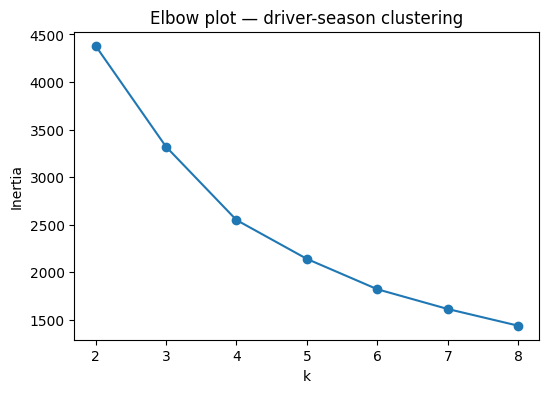

In [3]:
# Elbow check — run this once to pick k, then hardcode it below rather than
# re-searching every run
inertias = []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(k_range), inertias, marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow plot — driver-season clustering')
plt.show()


In [4]:
K = 4  # adjust based on the elbow plot above; 4 maps well to a
        # front-runner / solid midfield / inconsistent / backmarker framing

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
driver_season_features['DriverClusterID'] = kmeans.fit_predict(X_scaled)

# Label clusters by their mean PointsPerRace so the ID ordering is human-readable
cluster_order = (
    driver_season_features.groupby('DriverClusterID')['PointsPerRace']
    .mean().sort_values(ascending=False).index.tolist()
)
cluster_labels = {cid: f"Tier {i+1}" for i, cid in enumerate(cluster_order)}
driver_season_features['DriverClusterLabel'] = driver_season_features['DriverClusterID'].map(cluster_labels)

driver_season_features.groupby('DriverClusterLabel')[feature_cols].mean().round(2)


,AvgGridPosition,AvgFinishPosition,DNFRate,PointsPerRace
DriverClusterLabel,,,,
Tier 1,4.54,4.06,0.11,12.44
Tier 2,6.68,5.01,0.33,2.80
Tier 3,16.02,11.85,0.34,0.46
Tier 4,12.04,8.59,0.71,0.26


## 2. Pit Stop Clustering — Data-Driven Strategic Windows

Clusters pit stops by duration and lap number, per circuit, to identify strategic
window clusters more robust than a single circuit-wide average — directly informs
KPI #17 (Average Pit Window Variance).


In [5]:
pit_with_circuit = pit_stops_df.merge(
    races_df[['raceId', 'circuitId']], on='raceId', how='left'
)
pit_with_circuit = pit_with_circuit.dropna(subset=['DurationMs', 'lap'])

# Exclude anomalous stops (already flagged in etl.ipynb) so penalty/damage stops
# don't distort the clustering
pit_clean = pit_with_circuit[~pit_with_circuit.get('IsAnomalousStop', False)]

def cluster_pit_windows(group, k=2):
    if len(group) < k * 3:
        group = group.copy()
        group['PitWindowCluster'] = 0
        return group
    X = group[['lap']].values
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    group = group.copy()
    group['PitWindowCluster'] = km.fit_predict(X)
    return group

pit_clustered = (
    pit_clean
    .groupby('circuitId', group_keys=False)
    .apply(lambda g: cluster_pit_windows(g, k=2))
)

pit_window_summary = (
    pit_clustered
    .groupby(['circuitId', 'PitWindowCluster'])
    .agg(AvgLap=('lap', 'mean'), LapStd=('lap', 'std'), StopCount=('lap', 'size'))
    .reset_index()
    .sort_values(['circuitId', 'AvgLap'])
)

pit_window_summary.head(15)


C:\Users\harut\AppData\Local\Temp\ipykernel_15188\3407684584.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: cluster_pit_windows(g, k=2))


,circuitId,PitWindowCluster,AvgLap,LapStd,StopCount
0,1,0,13.105618,7.044267,445
1,1,1,36.121076,6.903421,446
3,2,1,14.714953,6.976915,428
2,2,0,35.887978,6.068199,366
4,3,0,15.323755,6.475153,522
5,3,1,37.908297,7.180107,458
7,4,1,18.808311,6.943839,746
6,4,0,42.837246,6.689846,639
8,5,0,15.429379,6.863675,177
9,5,1,39.033898,5.810354,177


## 3. Outlier Detection — Anomalous Stops & Laps

`IsAnomalousStop` (>60s) was already flagged in `etl.ipynb` with a simple threshold.
Here it's cross-checked with Isolation Forest, and lap times are flagged separately
for likely safety-car laps, so pace/degradation measures elsewhere aren't distorted
by laps that were never representative of green-flag racing pace.


In [6]:
# Cross-check the simple threshold rule against Isolation Forest
iso_pit = IsolationForest(contamination=0.02, random_state=42)
pit_valid = pit_stops_df.dropna(subset=['DurationMs']).copy()
pit_valid['IsOutlier_IsoForest'] = iso_pit.fit_predict(pit_valid[['DurationMs']]) == -1

print("Threshold rule flagged:", pit_valid['IsAnomalousStop'].sum() if 'IsAnomalousStop' in pit_valid else 'N/A')
print("Isolation Forest flagged:", pit_valid['IsOutlier_IsoForest'].sum())


Threshold rule flagged: 0
Isolation Forest flagged: 431


In [7]:
# Lap time outliers, computed PER RACE (a lap time that's normal at a street circuit
# would be an outlier at a high-speed track, so this can't be done globally)
def flag_lap_outliers(group):
    q1, q3 = group['LapTimeMs'].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    group = group.copy()
    group['IsAnomalousLap'] = group['LapTimeMs'] > upper_bound
    return group

lap_times_flagged = (
    lap_times_df.dropna(subset=['LapTimeMs'])
    .groupby('raceId', group_keys=False)
    .apply(flag_lap_outliers)
)

print(f"Flagged {lap_times_flagged['IsAnomalousLap'].sum():,} anomalous laps "
      f"out of {len(lap_times_flagged):,} ({lap_times_flagged['IsAnomalousLap'].mean():.2%})")
print("These are typically safety car / VSC laps and should be excluded from pure pace measures.")


Flagged 74,975 anomalous laps out of 874,784 (8.57%)
These are typically safety car / VSC laps and should be excluded from pure pace measures.


C:\Users\harut\AppData\Local\Temp\ipykernel_15188\425048912.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(flag_lap_outliers)


## 4. Reliability Regression — What Predicts a DNF?

Logistic regression predicting DNF probability from constructor, circuit, and season,
controlling for all three simultaneously — a sanity check against the single-slicer
DAX `Mechanical DNF Rate` findings (KPI #26), which only ever look at one factor at a time.


In [8]:
reg_data = results_df[['constructorId', 'circuitId', 'Season', 'IsDNF']].dropna()

# One-hot encode constructor & circuit; keep season as a numeric trend feature.
# For a first-pass model, cap dummy explosion by keeping only constructors/circuits
# with a reasonable sample size, folding everything else into 'Other'.
MIN_RACES = 20
top_constructors = reg_data['constructorId'].value_counts()
top_constructors = top_constructors[top_constructors >= MIN_RACES].index
reg_data['constructorId_grouped'] = reg_data['constructorId'].where(
    reg_data['constructorId'].isin(top_constructors), other=-1
)

X = pd.get_dummies(
    reg_data[['constructorId_grouped', 'circuitId']].astype(str),
    drop_first=True
)
X['Season'] = reg_data['Season']
y = reg_data['IsDNF'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred_proba = log_reg.predict_proba(X_test)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_test, y_pred_proba), 3))
print(classification_report(y_test, log_reg.predict(X_test)))


ROC AUC: 0.724
              precision    recall  f1-score   support

           0       0.70      0.76      0.73      3916
           1       0.63      0.56      0.59      2915

    accuracy                           0.67      6831
   macro avg       0.66      0.66      0.66      6831
weighted avg       0.67      0.67      0.67      6831



C:\Users\harut\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [9]:
# Which constructor/circuit dummy variables carry the strongest DNF-risk signal
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': log_reg.coef_[0]
}).sort_values('coefficient', ascending=False)

print("Highest DNF-risk factors:")
print(coef_df.head(10))
print("\nLowest (most protective) factors:")
print(coef_df.tail(10))


Highest DNF-risk factors:
                     feature  coefficient
74  constructorId_grouped_42     2.283895
75  constructorId_grouped_44     1.682437
76  constructorId_grouped_45     1.662673
78  constructorId_grouped_48     1.659496
62  constructorId_grouped_30     1.606930
77  constructorId_grouped_46     1.581367
68  constructorId_grouped_36     1.571901
92  constructorId_grouped_60     1.526748
70  constructorId_grouped_39     1.503976
79  constructorId_grouped_49     1.205942

Lowest (most protective) factors:
                       feature  coefficient
49   constructorId_grouped_211    -1.438721
54    constructorId_grouped_23    -1.439463
48   constructorId_grouped_210    -1.503276
50   constructorId_grouped_213    -1.511801
46   constructorId_grouped_209    -1.575085
102    constructorId_grouped_9    -1.621303
51   constructorId_grouped_214    -1.717518
37     constructorId_grouped_2    -1.805058
52   constructorId_grouped_215    -1.809869
13   constructorId_grouped_131    -1.

## 5. Season Points Forecasting

A simple trend-based projection of a driver/constructor's likely final points total
from a partial season, using the rolling-form feature already computed in
`feature_engineering.ipynb`. Shown as a "projected finish" reference line on Page 1.


In [10]:
def project_season_points(driver_id, season, results_df, races_df):
    """Projects end-of-season points using the driver's per-race average rate
    from the races completed so far, applied to the remaining scheduled races."""
    season_races = races_df[races_df['Season'] == season]
    total_races_scheduled = season_races['Round'].nunique()

    driver_races = results_df[
        (results_df['driverId'] == driver_id) & (results_df['Season'] == season)
    ].sort_values('Round')

    races_completed = driver_races['Round'].nunique()
    points_so_far = driver_races['points'].sum()

    if races_completed == 0:
        return np.nan

    avg_points_per_race = points_so_far / races_completed
    remaining_races = max(total_races_scheduled - races_completed, 0)
    projected_final_points = points_so_far + avg_points_per_race * remaining_races

    return round(projected_final_points, 1)


# Example usage — replace with a real driverId/season from your data once loaded
example_driver_id = results_df['driverId'].iloc[0]
example_season = results_df['Season'].iloc[0]

projected = project_season_points(example_driver_id, example_season, results_df, races_df)
print(f"Driver {example_driver_id}, Season {example_season} — projected final points: {projected}")


Driver 1, Season 2008 — projected final points: 98.0


In [11]:
# Note on modeling honesty: this is a flat-rate linear projection, not a proper
# time-series forecast — it assumes the driver's rate of scoring stays constant for
# the rest of the season, which ignores car development trends and circuit-fit
# effects covered elsewhere in this platform (e.g. Development Trajectory Score).
# A more rigorous version would weight recent races more heavily (exponential
# smoothing / Holt-Winters) rather than a flat average — documented here as a
# known simplification, consistent with how approximation measures are flagged
# throughout dax/DAX_Measures_Library.md.


## 6. Race Pace & Degradation Analysis

Fits a linear slope to each driver's stint lap times to quantify tire degradation
rate per stint. Exported as `DegradationSlope`, consumed directly by Dashboard Page 6.


In [12]:
def fit_stint_degradation(race_id, driver_id, start_lap, end_lap, lap_times_df):
    """Fits LapTimeMs ~ lap_within_stint via simple linear regression, returns the
    slope (ms/lap) as a degradation rate. Excludes anomalous (safety-car-affected)
    laps if that flag is present, since a caution period would flatten or invert
    the slope in a way that has nothing to do with tire degradation."""
    stint_laps = lap_times_df[
        (lap_times_df['raceId'] == race_id) &
        (lap_times_df['driverId'] == driver_id) &
        (lap_times_df['lap'] >= start_lap) &
        (lap_times_df['lap'] <= end_lap)
    ].dropna(subset=['LapTimeMs']).sort_values('lap')

    if len(stint_laps) < 4:  # too short a stint to fit a meaningful trend
        return np.nan

    X = (stint_laps['lap'] - stint_laps['lap'].min()).values.reshape(-1, 1)
    y = stint_laps['LapTimeMs'].values

    model = LinearRegression()
    model.fit(X, y)
    return model.coef_[0]  # milliseconds per lap — positive = degrading pace


if not stints_df.empty:
    stints_df['DegradationSlope'] = stints_df.apply(
        lambda r: fit_stint_degradation(
            r['raceId'], r['driverId'], r['StartLap'], r['EndLap'], lap_times_df
        ),
        axis=1
    )

stints_df.sort_values('DegradationSlope', ascending=False).head(10)


,raceId,driverId,StintNumber,StartLap,EndLap,LapCount,AvgStintLapTimeMs,DegradationSlope
27062,353,810,1,1,4,4,875366.000000,816916.200000
21458,78,11,2,17,22,6,384324.166667,263168.257143
34135,1080,840,4,25,29,5,350073.800000,237858.100000
1226,420,184,1,1,7,7,697242.714286,207000.821429
13113,948,835,2,13,18,6,286968.166667,162849.628571
35162,1100,858,3,3,8,6,262601.000000,143715.657143
35169,1100,815,3,3,8,6,261369.166667,143147.400000
288,470,110,1,1,4,4,245748.750000,138470.700000
34123,1080,848,3,23,29,7,271750.571429,130389.464286
34101,1080,20,3,24,30,7,269035.714286,127266.000000


## 7. Strategy Simulation — Undercut/Overcut Expected Value

A simplified Monte Carlo model estimating expected position change from pitting N
laps earlier/later than a rival, parameterized per circuit using the historical
undercut-gain data already validated in `sql/analytical_queries.sql` (Q6). This is
the most "senior" piece of the project — a light simulation model rather than a
purely descriptive one.


{'mean_gain': np.float64(0.79), 'p10': np.float64(-0.78), 'p50': np.float64(0.78), 'p90': np.float64(2.34), 'prob_gain_positive': np.float64(0.747)}


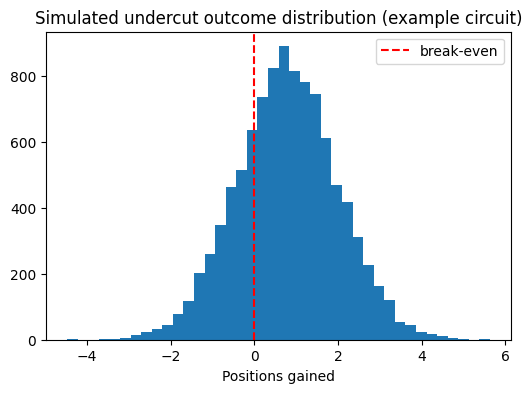

In [13]:
def simulate_undercut(circuit_avg_gain, circuit_gain_std, n_simulations=10000, random_state=42):
    """Monte Carlo simulation of undercut outcomes at a given circuit, using the
    historical mean and standard deviation of positions gained post-stop (from the
    SQL Q6 analysis) as the parameters of a normal distribution. Returns the
    simulated distribution of outcomes and summary stats."""
    rng = np.random.default_rng(random_state)
    simulated_gains = rng.normal(loc=circuit_avg_gain, scale=circuit_gain_std, size=n_simulations)

    return {
        'mean_gain': round(simulated_gains.mean(), 2),
        'p10': round(np.percentile(simulated_gains, 10), 2),
        'p50': round(np.percentile(simulated_gains, 50), 2),
        'p90': round(np.percentile(simulated_gains, 90), 2),
        'prob_gain_positive': round((simulated_gains > 0).mean(), 3),
        'raw_samples': simulated_gains,
    }


# Example: replace circuit_avg_gain / circuit_gain_std with your actual SQL Q6 output
# per circuit before relying on this for real strategy recommendations.
example_result = simulate_undercut(circuit_avg_gain=0.8, circuit_gain_std=1.2)
print({k: v for k, v in example_result.items() if k != 'raw_samples'})

plt.figure(figsize=(6, 4))
plt.hist(example_result['raw_samples'], bins=40)
plt.axvline(0, color='red', linestyle='--', label='break-even')
plt.title('Simulated undercut outcome distribution (example circuit)')
plt.xlabel('Positions gained')
plt.legend()
plt.show()


In [14]:
# Run the simulation per circuit using real Q6 SQL output, then export a lookup
# table Power BI can join on CircuitID for a "should we undercut here" reference.
#
# undercut_params = pd.read_csv('sql_q6_output.csv')  # circuit_name, avg_gain, gain_std
# undercut_simulation_results = []
# for _, row in undercut_params.iterrows():
#     res = simulate_undercut(row['avg_gain'], row['gain_std'])
#     undercut_simulation_results.append({
#         'circuit_name': row['circuit_name'],
#         'mean_gain': res['mean_gain'],
#         'p10': res['p10'], 'p90': res['p90'],
#         'prob_gain_positive': res['prob_gain_positive'],
#     })
# pd.DataFrame(undercut_simulation_results).to_parquet(OUT_DIR / 'undercut_simulation.parquet')
print("Wire in real per-circuit avg_gain/gain_std from SQL Q6 output before exporting.")


Wire in real per-circuit avg_gain/gain_std from SQL Q6 output before exporting.


## 8. Export Advanced Analytics Outputs

Each output below merges into the Power BI model as a static column/lookup — none of
these recompute per filter context, which is exactly why they belong here and not in DAX.


In [15]:
driver_season_features[['Season', 'driverId', 'DriverClusterID', 'DriverClusterLabel']] \
    .to_parquet(OUT_DIR / 'driver_clusters.parquet', index=False)

pit_window_summary.to_parquet(OUT_DIR / 'pit_window_clusters.parquet', index=False)

lap_times_flagged[['raceId', 'driverId', 'lap', 'IsAnomalousLap']] \
    .to_parquet(OUT_DIR / 'anomalous_laps.parquet', index=False)

coef_df.to_parquet(OUT_DIR / 'dnf_regression_coefficients.parquet', index=False)

stints_df.to_parquet(OUT_DIR / 'stints_with_degradation.parquet', index=False)

print("Advanced analytics outputs written to", OUT_DIR)
for f in OUT_DIR.glob('*.parquet'):
    print(" -", f.name)


Advanced analytics outputs written to ..\data\advanced
 - anomalous_laps.parquet
 - dnf_regression_coefficients.parquet
 - driver_clusters.parquet
 - pit_window_clusters.parquet
 - stints_with_degradation.parquet
